# OrthoRing Example: Kerr Ringdown Analysis of a Kerr QNM Injection

This notebook demonstrates Bayesian inference of black-hole ringdown signals using [OrthoRing](https://github.com/motoki-suzuki/OrthoRing).

We consider a **zero-noise injection** consisting of the Kerr $(2,2,0)$ and $(2,2,1)$ quasinormal modes (QNMs), observed by the LIGO Hanford and Livingston detectors. Unlike the companion [agnostic-model example](agnostic_model.ipynb), this analysis **assumes the Kerr QNM spectrum**: the two modes share a remnant mass $M_f$ and dimensionless spin $\chi_f$, which determine their frequencies and damping rates.

The likelihood uses Gram–Schmidt orthonormalized templates and analytically marginalizes over their mode coefficients.

The notebook covers the following steps:

1. Construct the noise autocorrelation function (ACF) from the Advanced LIGO design sensitivity.
2. Generate a zero-noise injection of the Kerr $(2,2,0)$ and $(2,2,1)$ modes.
3. Normalize the injected signal to a network signal-to-noise ratio (SNR) of 100.
4. Perform Bayesian parameter estimation using `OrthoRing`.
5. Visualize the posteriors and reconstruct the total and individual orthonormal-mode waveforms.

For details of the orthonormal ringdown analysis framework, see:

S. Morisaki, H. Motohashi, M. Suzuki, and D. Watarai, *Analyzing black-hole ringdowns with orthonormal modes*, [Phys. Rev. D **112**, 124083 (2025)](https://journals.aps.org/prd/abstract/10.1103/lhkp-w6hm), [arXiv:2507.12376 [gr-qc]](http://arxiv.org/abs/2507.12376).


## 1. Imports and Plotting Settings

Import the required libraries and configure the plotting style used throughout this notebook.

In [1]:
from pathlib import Path
import numpy as np
from scipy.interpolate import interp1d
import lal
import lalsimulation
import ringdown as rd

from orthoring import Likelihood, KerrFrequencyModel
from orthoring.kerrqnms import kerr_qnm_spectrum, kerr_qnm_excitation_factor

# ===== plotting settings =====
import matplotlib.pyplot as plt
import seaborn as sns
import corner
from matplotlib import patheffects

white_stroke = [patheffects.withStroke(linewidth=4, foreground="w")]
plt.style.use("default")
sns.set_palette("colorblind")
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.size"] = 16
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Computer Modern"
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["lines.solid_capstyle"] = "round"
plt.rcParams["lines.dash_capstyle"] = "round"
plt.rcParams["lines.solid_joinstyle"] = "round"
%matplotlib inline
%config InlineBackend.figure_format = "retina"

c_palette = {
    "primary": "#0173B2",
    "secondary": "#DE8F05",
}
c2_palette = {
    "primary": "#01476B",
    "secondary": "#915C03",
}

/var/folders/r8/5blr3vsn1bg04lfccgsb9yfr0000gn/T/ipykernel_68475/1050808779.py:4: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## 2. Injection and Analysis Settings

We consider a zero-noise injection consisting of the Kerr $(2,2,0)$ and $(2,2,1)$ QNMs, with a remnant black-hole mass of $M_f=70\,M_\odot$ and a dimensionless spin of $\chi_f=0.7$.

The signal is projected onto the LIGO Hanford (`H1`) and Livingston (`L1`) detectors and normalized to a network SNR of 100.

We use four real coefficients per mode ($D_{\mathrm{inj}}=4$) to generate the injection, while the subsequent agnostic analysis uses two coefficients per mode ($D=2$).


In [ ]:
DATA_PATH = Path("asd_data/aLIGODesign.txt")
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Missing ASD table: {DATA_PATH}. Place aLIGODesign.txt in examples/data/.")

modes = [(2,2,0), (2,2,1)]
n_modes = len(modes)
mf, chif = 70.0, 0.7
geocent_time = 1420878141.235932112
ra = 2.3332345218980706
dec = 0.1902435607590364
psi = 1.3289945095636535
ifos = ["H1", "L1"]
sampling_rate = 4096
duration = 0.05
D_inj = 4
D = 2
target_snr = 100.0

## 3. Noise Autocorrelation Function

`OrthoRing` evaluates the likelihood in the time domain using the noise ACF.

We first construct the one-sided noise power spectral density (PSD) from the Advanced LIGO design amplitude spectral density (ASD):

$$
S_n(f) = \mathrm{ASD}(f)^2.
$$

The PSD is linearly interpolated onto a uniform frequency grid with a frequency resolution of $\Delta f=1/256\,\mathrm{Hz}$.
Frequencies outside the range of the input ASD data are patched with a large PSD value ($10^{-38}\,\mathrm{Hz}^{-1}$).

We then compute the ACF from the interpolated and patched PSD using the [`ringdown`](https://github.com/maxisi/ringdown) package developed by Isi and collaborators.

The resulting ACF is used to construct the time-domain noise covariance matrix for likelihood evaluation.

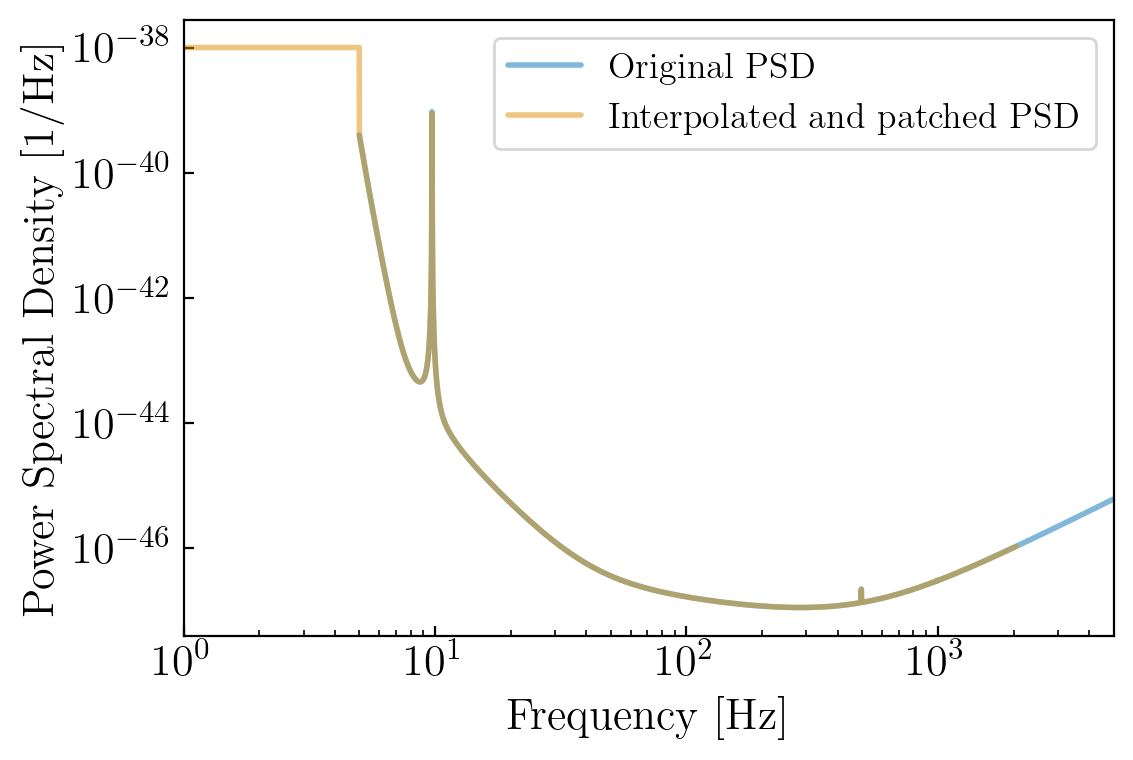

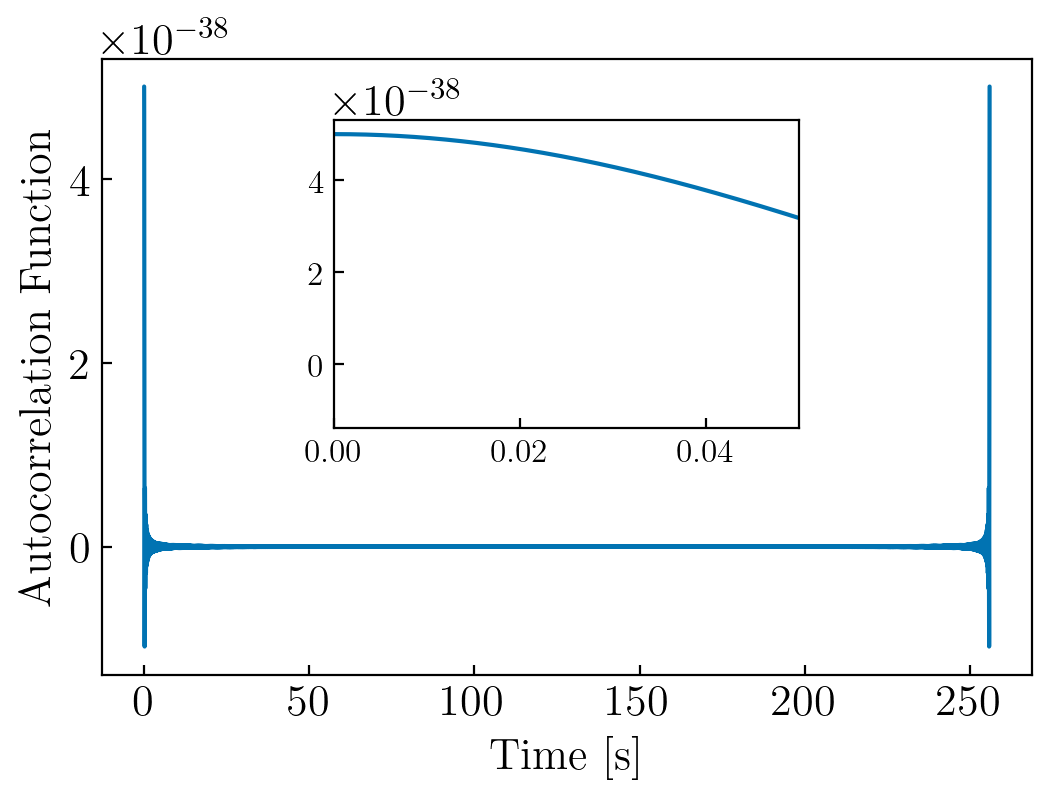

In [3]:
asd_table = np.loadtxt(DATA_PATH)
frequencies_asd, asd = asd_table[:, 0], asd_table[:, 1]
psd_interpolator = interp1d(
    frequencies_asd, asd**2, fill_value=1e-38, bounds_error=False
)
delta_f = 1 / 256
frequencies = np.arange(int(sampling_rate / (2 * delta_f)) + 1) * delta_f

plt.figure(figsize=(6, 4))
plt.loglog(frequencies_asd, asd**2, lw=2, alpha=0.5, label="Original PSD")
plt.loglog(frequencies, psd_interpolator(frequencies),
           lw=2, alpha=0.5, label="Interpolated and patched PSD")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power Spectral Density [1/Hz]")
plt.xlim(1, 5000)
plt.legend(fontsize=13)
plt.show()


acf_dict = {}
acf_plot_dict = {}
for ifo in ifos:
    psd_series = rd.data.PowerSpectrum(
        psd_interpolator(frequencies),
        index=frequencies,
        ifo=ifo,
    )
    acf = psd_series.to_acf()
    acf_dict[ifo] = np.asarray(acf.values)
    acf_plot_dict[ifo] = acf

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(acf_plot_dict["H1"].index, acf_plot_dict["H1"].values)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Autocorrelation Function")

inset_ax = ax.inset_axes([0.25, 0.4, 0.5, 0.5])
inset_ax.plot(acf_plot_dict["H1"].index, acf_plot_dict["H1"].values)
inset_ax.set_xlim(0, duration)
inset_ax.tick_params(labelsize=12)
plt.show()

## 4. Signal Injection

We generate a zero-noise ringdown signal consisting of the Kerr $(2,2,0)$ and $(2,2,1)$ QNMs.

The complex QNM frequencies $\omega_{\ell mn}$ and excitation factors $B_{\ell mn}$ are obtained using the Kerr QNM data included in `OrthoRing`.

We define the reference complex amplitudes as　$\mathcal{A}_{\ell mn} = B_{\ell mn}/\omega_{\ell mn}^{2}$, where the frequencies and excitation factors are evaluated in units of the remnant black-hole mass.

The corresponding reference coefficients in the `combined_coeff` parametrization with $D_{\mathrm{inj}}=4$ are

$$
\mathbf{c}_{\ell mn}
=
\left(
2\operatorname{Re}\mathcal{A}_{\ell mn},
2\operatorname{Im}\mathcal{A}_{\ell mn},
0,0
\right).
$$

The physical oscillation frequencies and damping rates are obtained from $f_{\ell mn}=\operatorname{Re}\omega_{\ell mn}/2\pi$, $\gamma_{\ell mn}=-\operatorname{Im}\omega_{\ell mn}$, where $\omega_{\ell mn}$ is now expressed in inverse seconds.

In [4]:
fs_true, gs_true, a_ref = [], [], []
for ell, m, n in modes:
    omega_dimensionless = kerr_qnm_spectrum(ell=ell, m=m, n=n, chif=chif)
    B = kerr_qnm_excitation_factor(ell=ell, m=m, n=n, chif=chif)
    a_ref.append(B / omega_dimensionless**2)
    omega = kerr_qnm_spectrum(ell=ell, m=m, n=n, chif=chif, mf=mf)
    fs_true.append(np.real(omega) / (2 * np.pi))
    gs_true.append(-np.imag(omega))
fs_true, gs_true = np.asarray(fs_true), np.asarray(gs_true)
coeffs_ref = np.asarray(
    [value for a in a_ref for value in (2 * np.real(a), 2 * np.imag(a), 0, 0)]
)
print("Injected frequencies [Hz]:", fs_true)
print("Injected damping rates [1/s]:", gs_true)


Injected frequencies [Hz]: [245.85210273 240.57155729]
Injected damping rates [1/s]: [234.32870235 708.37990251]


### Detector Response

The ringdown signal is projected onto the LIGO Hanford (`H1`) and Livingston (`L1`) detectors using their antenna response functions, $F_+$ and $F_\times$.

We use `LALSuite` to calculate the detector responses and the arrival-time delays relative to the geocenter.

The resulting detector strains are generated as superpositions of damped sinusoids, starting at the detector-frame ringdown onset times.

In [5]:
def generate_detector_strain(coeffs, frequencies, damping_rates):
    """Return per-detector times, zero-noise strains, and detector onset times."""
    N = int(sampling_rate * duration)
    t = np.arange(N) / sampling_rate
    gmst = lal.GreenwichMeanSiderealTime(geocent_time)
    gps = lal.LIGOTimeGPS(geocent_time)
    time_dict, data_dict, start_time_dict = {}, {}, {}

    for ifo in ifos:
        detector = lalsimulation.DetectorPrefixToLALDetector(ifo)
        Fp, Fc = lal.ComputeDetAMResponse(detector.response, ra, dec, psi, gmst)
        delay = lal.TimeDelayFromEarthCenter(detector.location, ra, dec, gps)
        start_time = geocent_time + delay
        templates = []
        for f, g in zip(frequencies, damping_rates):
            decay = np.exp(-g * t)
            coswt = np.cos(2 * np.pi * f * t)
            sinwt = np.sin(2 * np.pi * f * t)
            templates.extend((
                Fp * decay * coswt,
                Fp * decay * sinwt,
                Fc * decay * coswt,
                Fc * decay * sinwt,
            ))
        data_dict[ifo] = np.asarray(coeffs) @ np.asarray(templates)
        time_dict[ifo] = start_time + t
        start_time_dict[ifo] = start_time

    return data_dict, time_dict, start_time_dict

data_ref, time_dict, start_time_dict = generate_detector_strain(
    coeffs_ref, fs_true, gs_true
)

### Network SNR Normalization

The reference signal is rescaled to achieve a target network SNR of 100.

The network SNR is calculated using the noise-weighted inner product implemented in `OrthoRing`, $\rho^2=\sum_I (h_I|h_I)$, where $I$ labels the detectors.

The reference coefficients are then rescaled as $\mathbf{c}_{\mathrm{inj}}=(\rho_{\mathrm{target}}/\rho_{\mathrm{ref}})\mathbf{c}_{\mathrm{ref}}$, with $\rho_{\mathrm{target}}=100$.

The resulting detector strains are used as the zero-noise injection data for the subsequent Bayesian analysis.

Reference SNR: 2660732805554398298112.0000
Target network SNR: 100.0


/opt/anaconda3/envs/ringdown/lib/python3.11/site-packages/bilby/core/likelihood.py:127: FutureWarning: Setting non-trivial parameters for <class 'orthoring.likelihood.Likelihood'>. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(msg, FutureWarning)


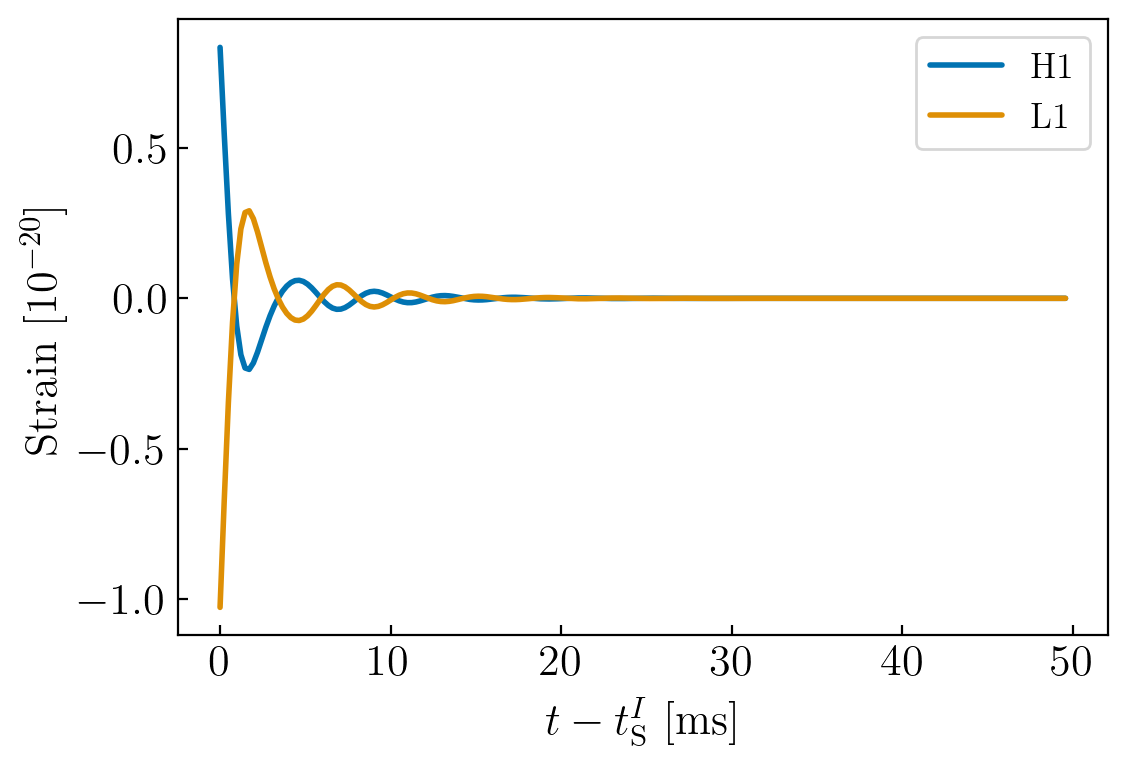

In [6]:
# The reference likelihood is needed only for noise-weighted SNR normalization.
frequency_model_ref = KerrFrequencyModel(mode_array=modes)
likelihood_ref = Likelihood(
    data_dict=data_ref,
    time_dict=time_dict,
    ra=ra,
    dec=dec,
    psi=psi,
    D=D_inj,
    sampling_rate=sampling_rate,
    geocent_time=geocent_time,
    analysis_start_time=start_time_dict,
    auto_correlation_dict=acf_dict,
    frequency_model=frequency_model_ref,
    parametrization="combined_coeff",
)

snr_ref = np.sqrt(likelihood_ref.inner_product(
    likelihood_ref.whitened_data_dict,
    likelihood_ref.whitened_data_dict,
))
coeffs_inj = coeffs_ref * (target_snr / snr_ref)
data_dict, time_dict, start_time_dict = generate_detector_strain(
    coeffs_inj, fs_true, gs_true
)
print(f"Reference SNR: {snr_ref:.4f}")
print(f"Target network SNR: {target_snr:.1f}")

strain_scale = 1e20
fig, ax = plt.subplots(figsize=(6, 4))
for ifo in ifos:
    ax.plot((time_dict[ifo] - start_time_dict[ifo]) * 1000,
            data_dict[ifo] * strain_scale, label=ifo, lw=2)
ax.set_xlabel(r"$t-t_{\mathrm{S}}^{I}$ [ms]")
ax.set_ylabel(rf"Strain [$10^{{-{round(np.log10(strain_scale))}}}$]")
ax.legend(fontsize=13)
plt.show()


## 5. Orthonormal Kerr Inference

We perform Bayesian parameter estimation using `KerrFrequencyModel` with `mode_array=[(2,2,0), (2,2,1)]`. For each posterior sample, the mode frequencies and damping rates are determined by the remnant black-hole mass $M_f$ and dimensionless spin $\chi_f$ through the Kerr QNM spectrum.

We use orthonormalized damped-sinusoid templates with two real coefficients per mode ($D=2$). Setting `marginalized=True` analytically marginalizes the likelihood over these coefficients, allowing the nested sampler to explore only the two parameters $(M_f,\chi_f)$. The marginalized coefficients are subsequently recovered by sampling from their conditional posterior distributions.

For this demonstration, we adopt uniform priors on $M_f$ and $\chi_f$ (see the ranges specified below).


In [7]:
frequency_model = KerrFrequencyModel(
    mode_array=modes,
    mf_min=50.0,
    mf_max=100.0,
    chif_min=0.0,
    chif_max=0.99,
)
likelihood = Likelihood(
    data_dict=data_dict,
    time_dict=time_dict,
    ra=ra,
    dec=dec,
    psi=psi,
    D=D,
    sampling_rate=sampling_rate,
    geocent_time=geocent_time,
    analysis_start_time=start_time_dict,
    auto_correlation_dict=acf_dict,
    frequency_model=frequency_model,
    parametrization="combined_coeff",
    marginalized=True,
)


### Posterior Sampling

We sample the posterior distributions of $M_f$ and $\chi_f$ using `dynesty` through `Bilby`. Because the mode coefficients have been analytically marginalized, they are drawn afterward from their conditional posterior distributions with `resample_coefficients=True` for waveform reconstruction.

For simplicity, we use a single process (`npool=1`).
Parallel sampling can be enabled by increasing `npool` if supported by the execution environment.

In [8]:
result = likelihood.run_sampler(
    resample_coefficients=True,
    sampler="dynesty",
    npool=1,
    nlive=1000,
    outdir="results/kerr_model",
    label="run",
    resume=True,
)


15:04 bilby INFO    : Running for label 'run', output will be saved to 'results/kerr_model'
15:04 bilby INFO    : Analysis priors:
15:04 bilby INFO    : mf=Uniform(minimum=50.0, maximum=100.0, name='mf', latex_label='$M_f\\,[M_{\\odot}]$', unit=None, boundary=None)
15:04 bilby INFO    : chif=Uniform(minimum=0.0, maximum=0.99, name='chif', latex_label='$\\chi_f$', unit=None, boundary=None)
15:04 bilby INFO    : Analysis likelihood class: <class 'orthoring.likelihood.Likelihood'>
15:04 bilby INFO    : Analysis likelihood noise evidence: nan
15:04 bilby INFO    : Single likelihood evaluation took 3.012e-04 s
15:04 bilby INFO    : Using sampler Dynesty with kwargs {'nlive': 1000, 'bound': 'live', 'sample': 'act-walk', 'periodic': None, 'reflective': None, 'update_interval': 600, 'first_update': None, 'rstate': None, 'queue_size': 1, 'pool': None, 'use_pool': None, 'live_points': None, 'logl_args': None, 'logl_kwargs': None, 'ptform_args': None, 'ptform_kwargs': None, 'enlarge': None, 'boot

1it [00:00, ?it/s]

15:05 bilby INFO    : Written checkpoint file results/kerr_model/run_resume.pickle
/opt/anaconda3/envs/ringdown/lib/python3.11/site-packages/dynesty/plotting.py:252: RuntimeWarning: overflow encountered in exp
  np.exp(logwt), logz if logplot else np.exp(logz)
/opt/anaconda3/envs/ringdown/lib/python3.11/site-packages/dynesty/plotting.py:282: RuntimeWarning: overflow encountered in exp
  zspan = (0., 1.05 * np.exp(logz[-1] + 3. * logzerr[-1]))
15:05 bilby WARNING : Axis limits cannot be NaN or Inf
15:05 bilby WARNING : Failed to create dynesty run plot at checkpoint
15:05 bilby INFO    : Rejection sampling nested samples to obtain 2797 posterior samples
15:05 bilby INFO    : Sampling time: 0:00:43.334417
15:05 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 


15:05 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 
15:05 bilby INFO    : Summary of results:
nsamples: 2797
ln_noise_evidence:    nan
ln_evidence: 4987.787 +/-  0.092
ln_bayes_factor:    nan +/-  0.092

Sampling coefficients: 100%|██████████| 2797/2797 [00:19<00:00, 146.82it/s]
15:05 bilby INFO    : No extension given, defaulting to JSON.


## 6. Posterior Distributions

We show the posterior distributions of the remnant black-hole mass $M_f$, dimensionless spin $\chi_f$, and orthonormal-mode amplitudes $\tilde{A}_{\ell mn}$. The sampled values of $M_f$ and $\chi_f$ determine the $(2,2,0)$ and $(2,2,1)$ frequencies and damping rates through the Kerr spectrum.

The orthonormal-mode amplitudes are computed from the resampled coefficients,

$$
\tilde{A}_{\ell mn} = \sqrt{\sum_{j=0}^{D-1}\tilde{c}_{j,\ell mn}^{\,2}},
$$

where $\tilde{c}_{j,\ell mn}$ denotes the $j$-th coefficient of the $(\ell,m,n)$ orthonormal mode.


/opt/anaconda3/envs/ringdown/lib/python3.11/site-packages/bilby/core/likelihood.py:127: FutureWarning: Setting non-trivial parameters for <class 'orthoring.likelihood.Likelihood'>. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(msg, FutureWarning)


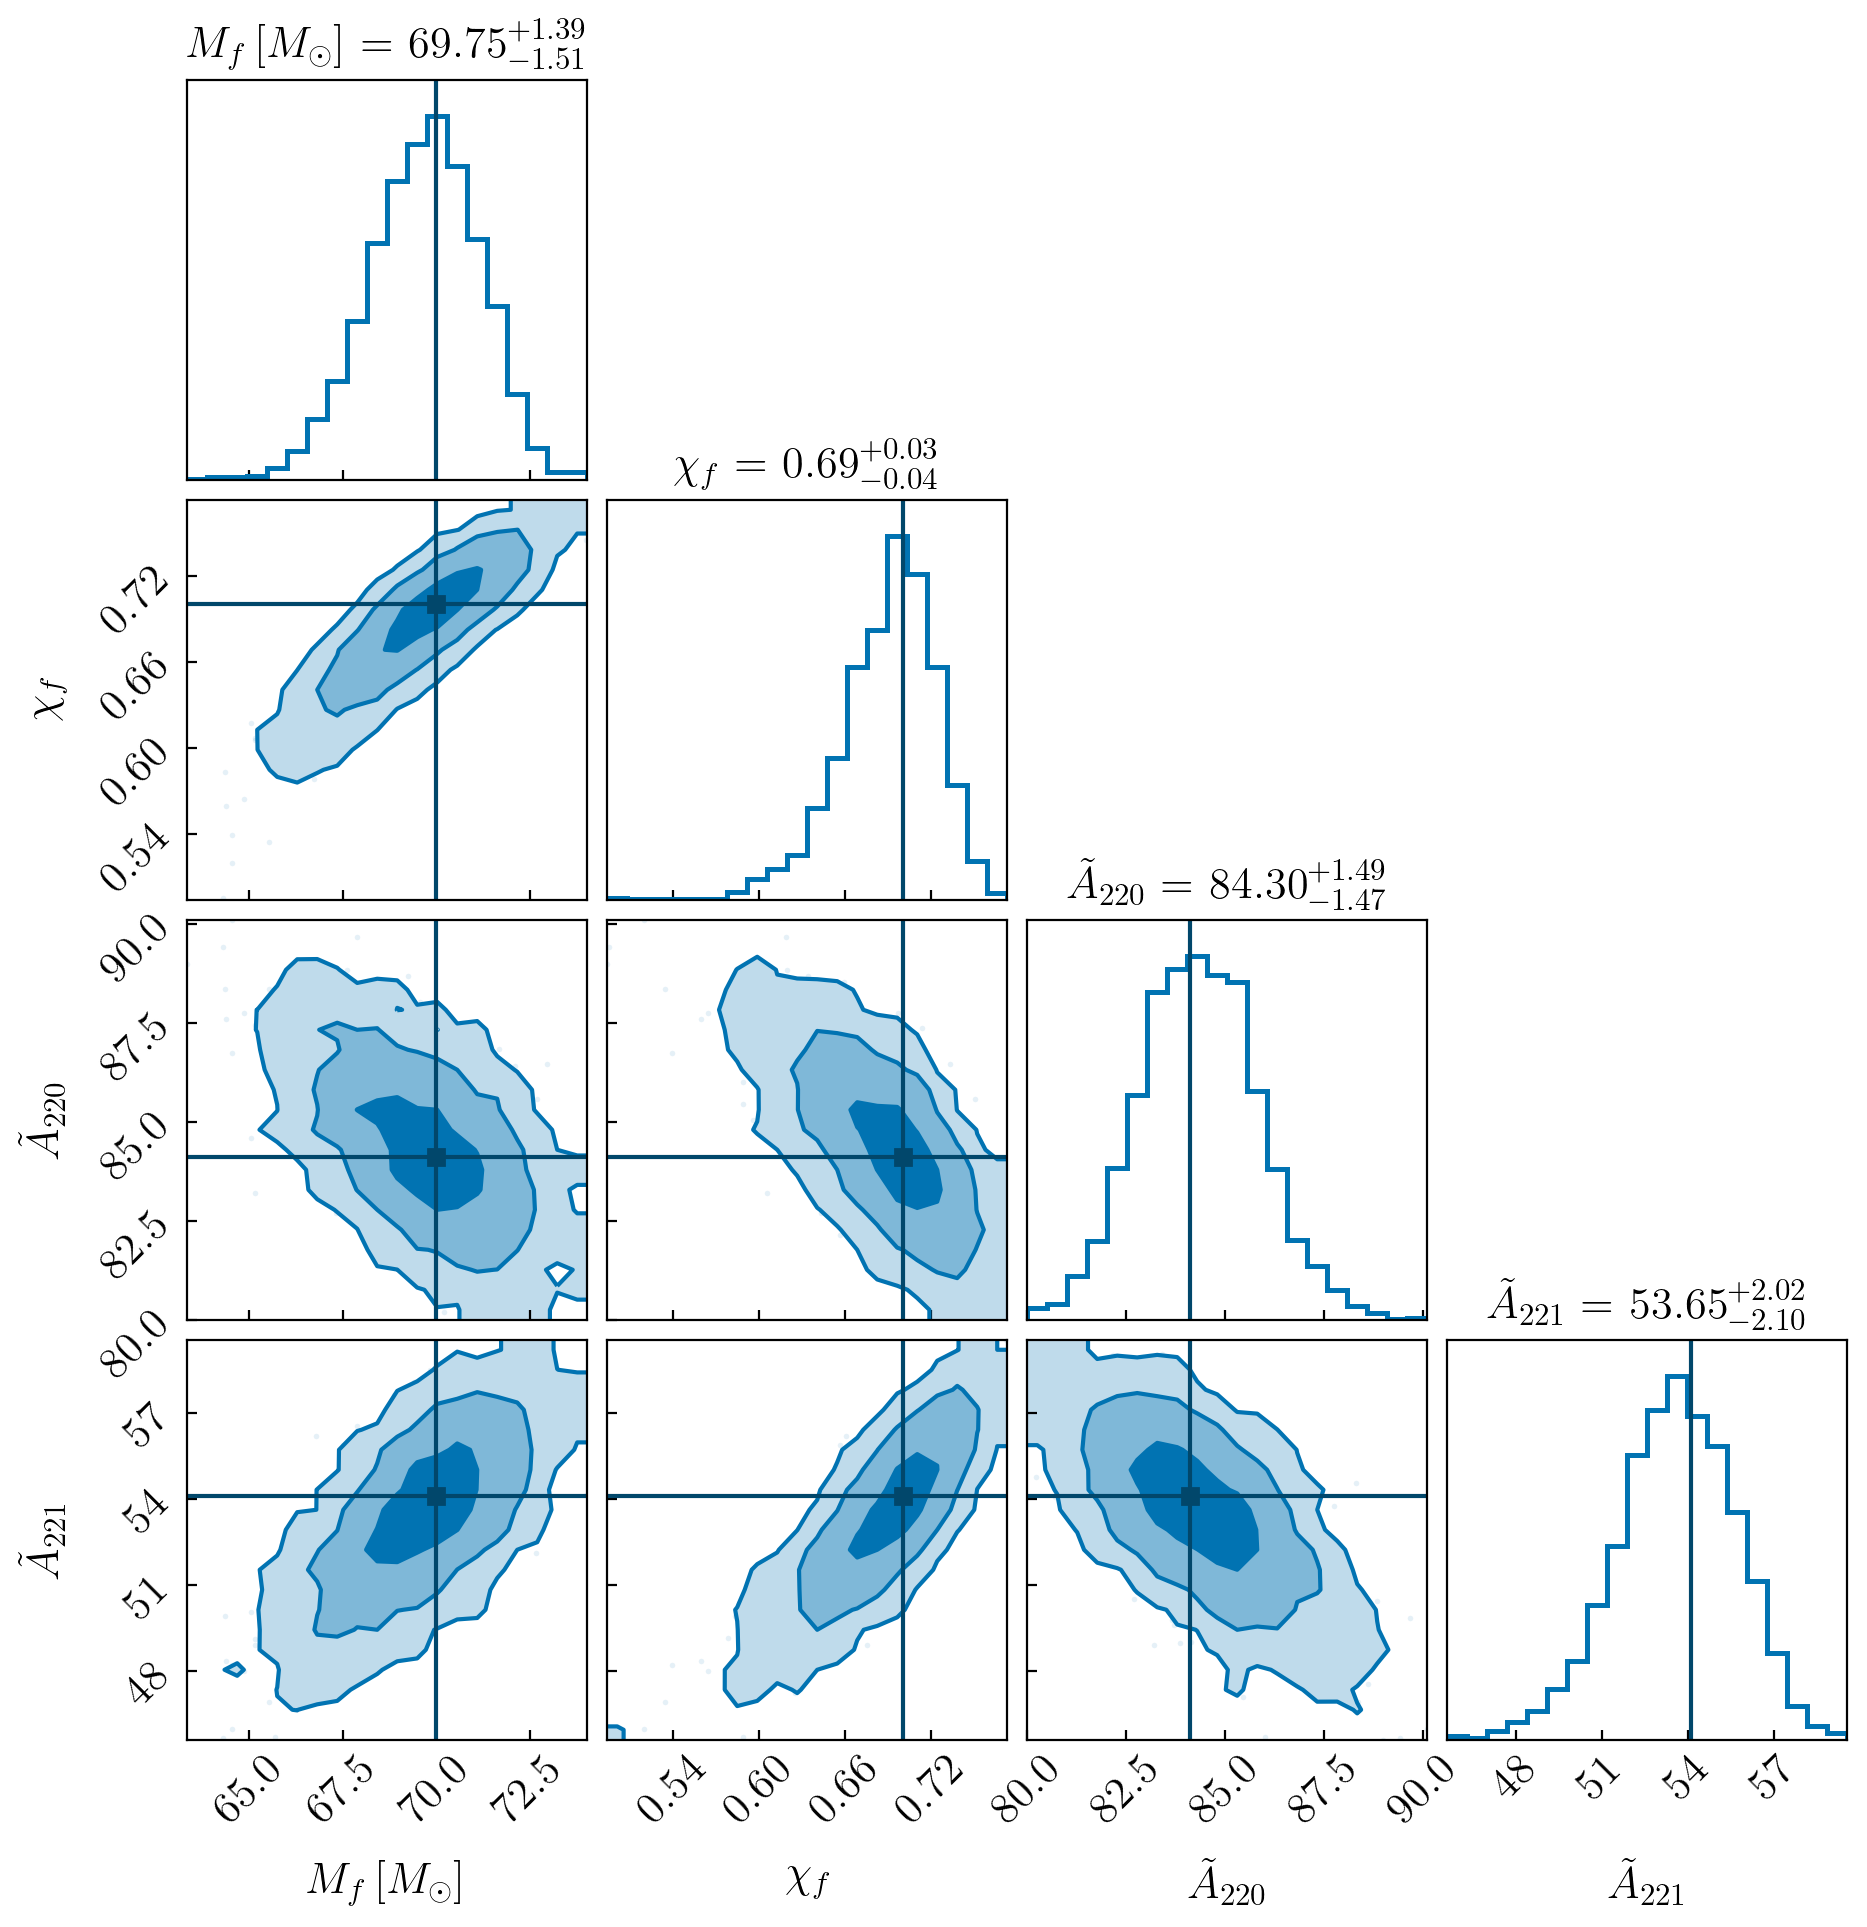

In [10]:
coeffs_inj_D2 = coeffs_inj.reshape(n_modes, D_inj)[:, :D].reshape(-1)
frequency_model_inj_basis = KerrFrequencyModel(mode_array=modes)
likelihood_inj_basis = Likelihood(
    data_dict=data_dict,
    time_dict=time_dict,
    ra=ra,
    dec=dec,
    psi=psi,
    D=D,
    sampling_rate=sampling_rate,
    geocent_time=geocent_time,
    analysis_start_time=start_time_dict,
    auto_correlation_dict=acf_dict,
    frequency_model=frequency_model_inj_basis,
    parametrization="combined_coeff",
)
_, Uinv_true_D2 = likelihood_inj_basis.get_U_matrix(fs_true, gs_true)
coeffs_ortho_inj_D2 = Uinv_true_D2 @ coeffs_inj_D2
ortho_amp_inj_D2 = np.linalg.norm(
    coeffs_ortho_inj_D2.reshape(n_modes, D), axis=1
)

columns = ["mf", "chif", "ortho_amp_220", "ortho_amp_221"]
posterior = result.posterior[columns].to_numpy()
truths = [mf, chif, *ortho_amp_inj_D2]
labels = [
    r"$M_f\,[M_\odot]$",
    r"$\chi_f$",
    r"$\tilde{A}_{220}$",
    r"$\tilde{A}_{221}$",
]

corner.corner(
    posterior,
    labels=labels,
    truths=truths,
    smooth=0.5,
    show_titles=True,
    title_kwargs={"fontsize": 16, "pad": 8},
    hist_kwargs={"linewidth": 1.8},
    levels=(0.393, 0.865, 0.989),
    fill_contours=True,
    color=c_palette["primary"],
    truth_color=c2_palette["primary"],
)
plt.show()


## 7. Waveform Reconstruction

We reconstruct the ringdown waveforms from the posterior samples using `Likelihood.reconstruct_waveforms()`.
The reconstructed strain in each detector is expressed as a superposition of orthonormal templates,
$$
h^I(t)
=
\sum_{\ell mn}
\sum_{j=0}^{D-1}
\tilde{c}_{j,\ell mn}\tilde{v}_{j,\ell mn}^{I}(t),
$$
where $I$ labels the detector and $D$ is the number of coefficients per mode.

We first compare the reconstructed total strain with the injected waveform in each detector.


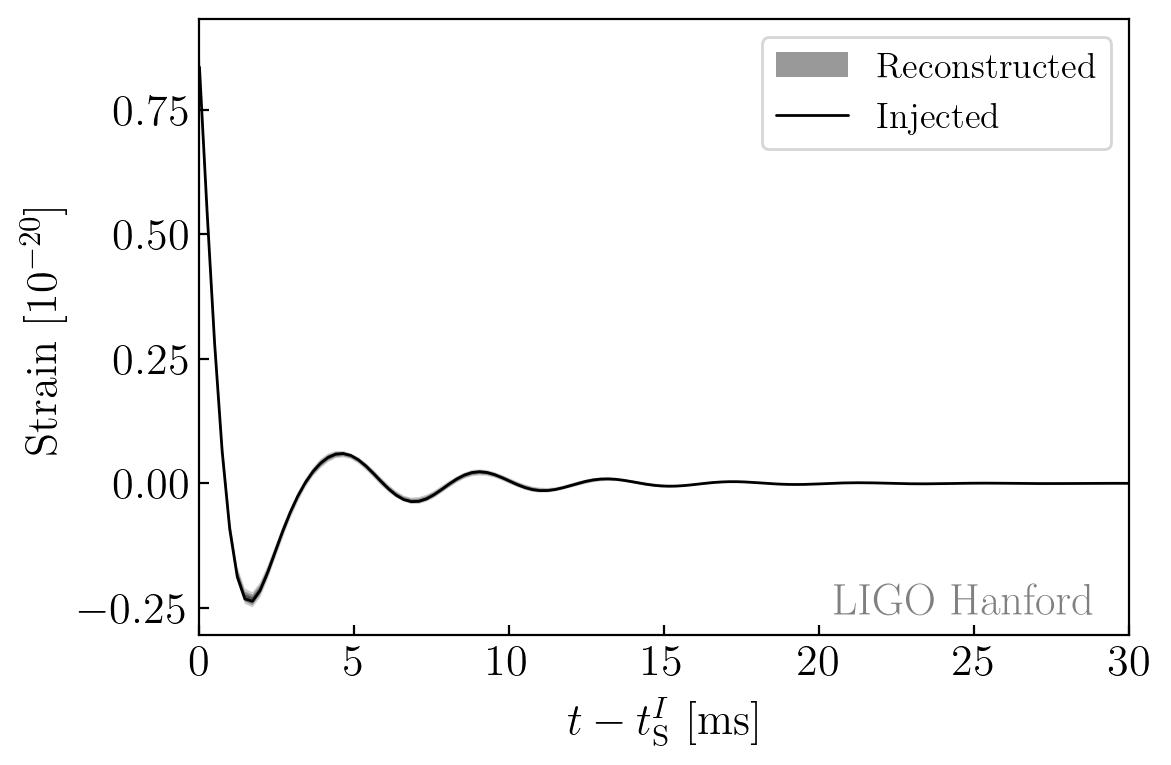

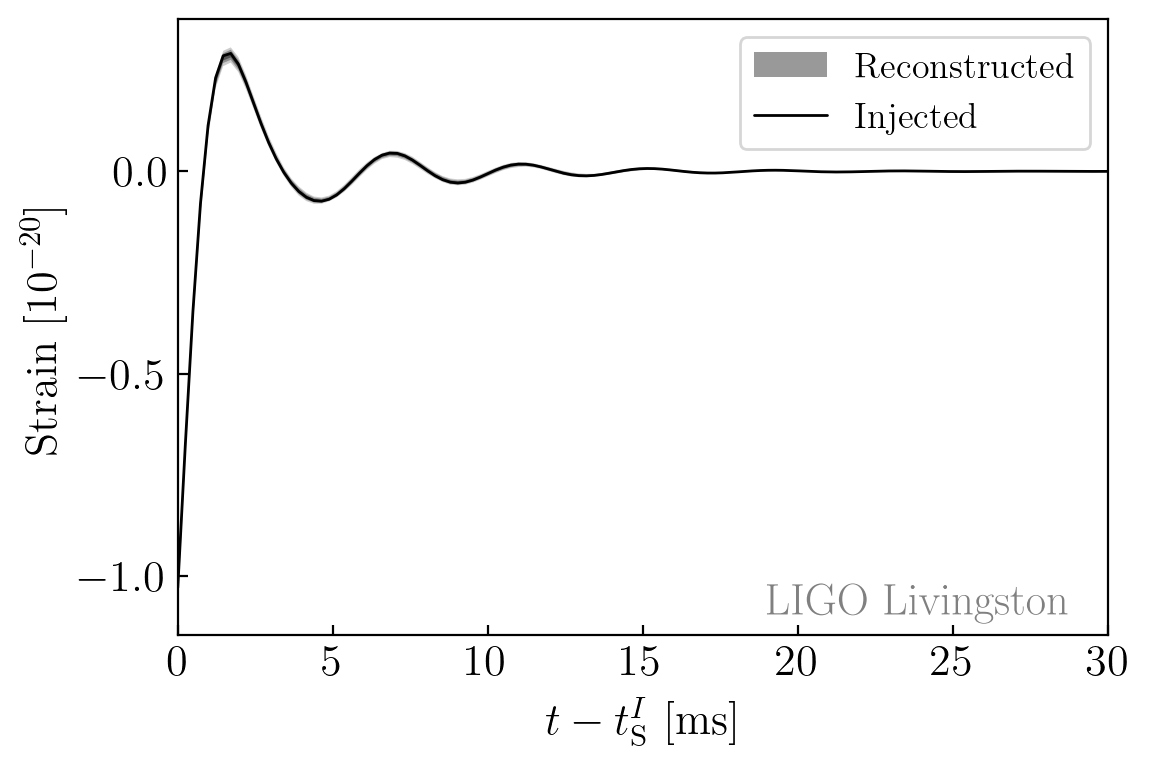

In [11]:
sigmas = [
    (0.135, 99.865, 0.20),
    (2.275, 97.725, 0.30),
    (15.865, 84.135, 0.4),
]
ifo_names = {
    "H1": "LIGO Hanford",
    "L1": "LIGO Livingston",
}

waveforms, mode_waveforms = likelihood.reconstruct_waveforms(result)

for ifo in ifos:
    fig, ax = plt.subplots(figsize=(6, 4))
    h = np.asarray(waveforms[ifo])
    t = (time_dict[ifo] - start_time_dict[ifo]) * 1000
    for lo_p, hi_p, alpha in sigmas:
        lo = np.percentile(h, lo_p, axis=0)
        hi = np.percentile(h, hi_p, axis=0)
        ax.fill_between(
            t,
            lo * strain_scale,
            hi * strain_scale,
            facecolor="black",
            alpha=alpha,
        )
    ax.fill_between(
        [], [], [],
        facecolor="black",
        alpha=0.4,
        label="Reconstructed",
    )
    ax.plot(
        t,
        data_dict[ifo] * strain_scale,
        color="black",
        lw=1,
        label="Injected",
    )
    ax.set_xlim(0, 30)
    ax.set_xlabel(r"$t-t_{\mathrm{S}}^{I}$ [ms]")
    ax.set_ylabel(rf"Strain [$10^{{-{round(np.log10(strain_scale))}}}$]")
    ax.legend(fontsize=13, loc="upper right")
    ax.text(
        0.98, 0.02,
        ifo_names[ifo],
        color="gray",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        path_effects=white_stroke,
    )
    plt.show()

### Individual Orthonormal Modes

We also reconstruct the contributions from the individual orthonormal modes.
For each mode $(\ell,m,n)$, the reconstructed waveform is given by
$$
\tilde{h}_{\ell mn}^I(t)=
\sum_{j=0}^{D-1}
\tilde{c}_{j,\ell mn}\tilde{v}_{j,\ell mn}^{I}(t).
$$
Unlike the total waveform, the decomposition into individual orthonormal modes depends on the choice of basis.
In particular, the orthonormal modes are not generally identical to the original Kerr QNMs.

We therefore compare the reconstructed orthonormal-mode waveforms with the injected signal decomposed into the corresponding orthonormal basis.

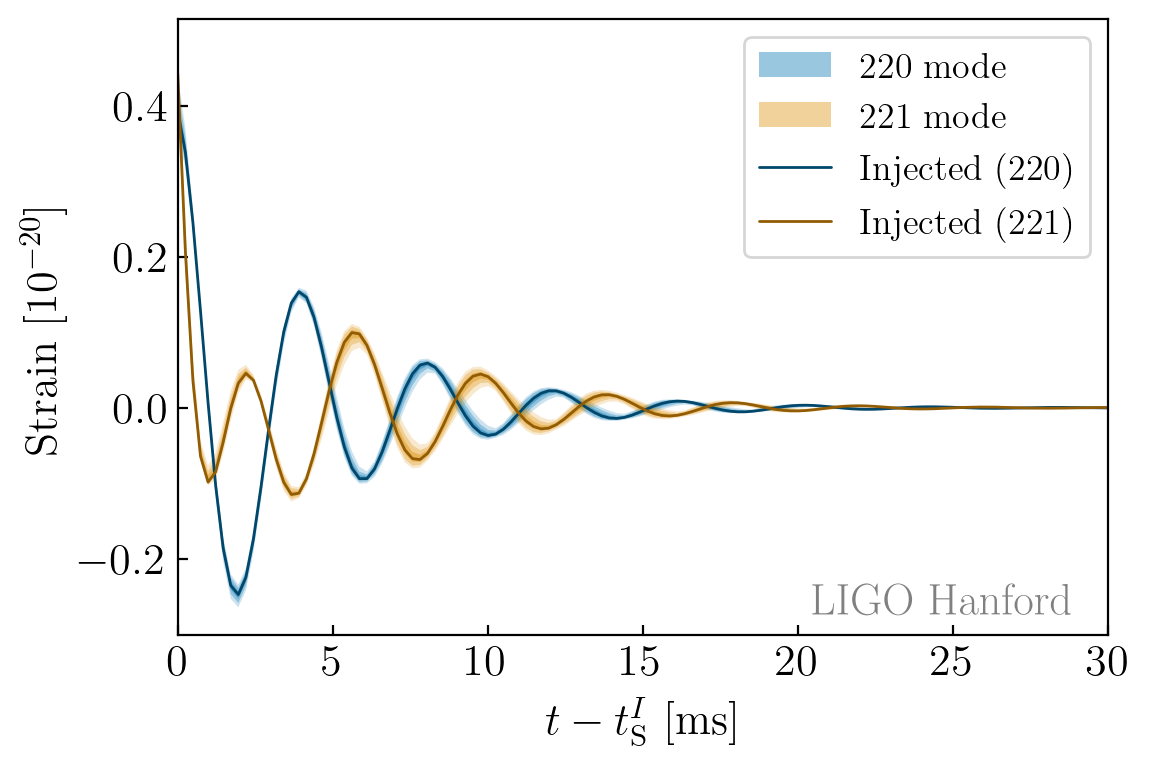

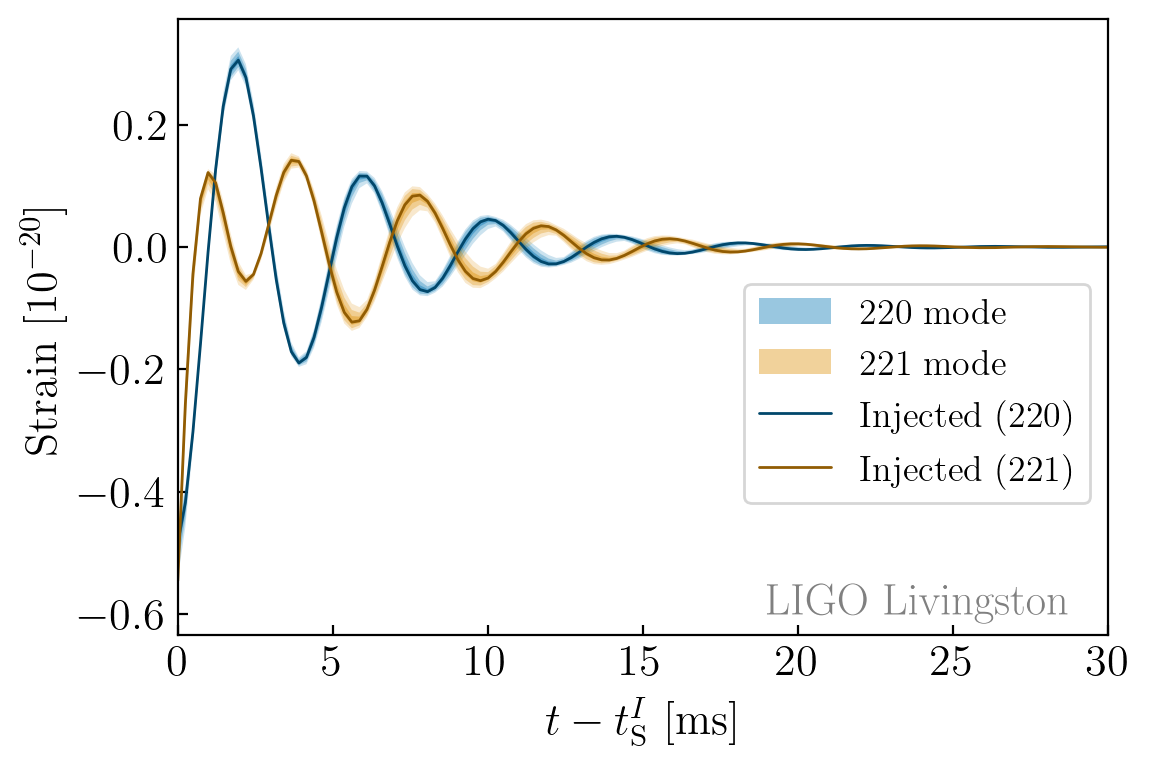

In [23]:
mode_keys = ["220", "221"]

ortho_templates_true, _ = likelihood_inj_basis.get_orthonormal_templates(fs_true, gs_true)

injected_ortho_modes = {key: {} for key in mode_keys}

for ifo in ifos:
    detector_templates = np.asarray([
        template[ifo] for template in ortho_templates_true
    ])

    for k, key in enumerate(mode_keys):
        j = k * D
        injected_ortho_modes[key][ifo] = (
            coeffs_ortho_inj_D2[j:j + D]
            @ detector_templates[j:j + D]
        )

for ifo in ifos:
    fig, ax = plt.subplots(figsize=(6, 4))

    t = (time_dict[ifo] - start_time_dict[ifo]) * 1000

    # Reconstructed orthonormal modes
    for k, color in zip(["220", "221"], [
        c_palette["primary"],
        c_palette["secondary"],
    ]):
        h = np.asarray(mode_waveforms[k][ifo])
        for lo_p, hi_p, alpha in sigmas:
            lo = np.percentile(h, lo_p, axis=0)
            hi = np.percentile(h, hi_p, axis=0)
            ax.fill_between(
                t,
                lo * strain_scale,
                hi * strain_scale,
                facecolor=color,
                alpha=alpha,
            )
    ax.fill_between(
        [], [], [],
        facecolor=c_palette["primary"],
        alpha=0.4,
        label="220 mode",
    )
    ax.fill_between(
        [], [], [],
        facecolor=c_palette["secondary"],
        alpha=0.4,
        label="221 mode",
    )
    ax.plot(
        t,
        injected_ortho_modes["220"][ifo] * strain_scale,
        color=c2_palette["primary"],
        lw=1,
        label="Injected (220)",
    )
    ax.plot(
        t,
        injected_ortho_modes["221"][ifo] * strain_scale,
        color=c2_palette["secondary"],
        lw=1,
        label="Injected (221)",
    )
    ax.set_xlim(0, 30)
    ax.set_xlabel(r"$t-t_{\mathrm{S}}^{I}$ [ms]")
    ax.set_ylabel(rf"Strain [$10^{{-{round(np.log10(strain_scale))}}}$]")
    if ifo == "H1":
        ax.legend(fontsize=13, loc="upper right")
    if ifo == "L1":
        ax.legend(
            fontsize=13,
            loc="upper right",
            bbox_to_anchor=(1, 0.6),
        )
    ax.text(
        0.98, 0.02,
        ifo_names[ifo],
        color="gray",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        path_effects=white_stroke,
    )
    plt.show()